In [1]:
import pandas as pd
import seaborn as sns
import umap.umap_ as umap
import os

In [2]:
import sys  
sys.path.insert(0, '/home/m.caros/work/3DSemanticSegmentation/')
from src.models.pointnet import ClassificationPointNet
from src.bt.utils_barlow import *
from src.datasets import BarlowTwinsDataset
from torch.utils.data import DataLoader
from src.models.pointnet2_sem_seg import PointNet2
from src.models.barlow_twins_PN2 import *


In [3]:
sys.path.insert(0, '/home/m.caros/work/3DSemanticSegmentation/utils')
from utils_plot import plot_3d_coords

In [4]:
BATCH_SIZE = 1
use_device = 'cuda'
encoder_out_dim = 512
hidden_projector_dim = 512
z_dim = 128

## Data

In [5]:
dataset_folder = '/dades/LIDAR/towers_detection/datasets/pc_40x40_4096p_v3'
n_points = 4096
c_sample = False

In [6]:
path_list_files='/home/m.caros/work/3DSemanticSegmentation/train_test_files/RGBN_40x40_barlow_10'

# Datasets train / val / test
with open(os.path.join(path_list_files, 'train_cls_files.txt'), 'r') as f:
    train_files = f.read().splitlines()
with open(os.path.join(path_list_files, 'train_labeled_cls_files.txt'), 'r') as f:
    val_files = f.read().splitlines()
with open(os.path.join(path_list_files, 'test_cls_files.txt'), 'r') as f:
    test_files = f.read().splitlines()

# paths_files = glob.glob('/dades/LIDAR/towers_detection/datasets/pc_40x40_4096p/pylon*')
# towers_files = [f.split('/')[-1] for f in paths_files]

In [7]:
# Initialize datasets
test_dataset = BarlowTwinsDataset(dataset_folder=dataset_folder,
                           task='classification', 
                           number_of_points=n_points,
                           files=test_files,
                           fixed_num_points=False,
                           use_ground=True)

In [8]:

test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, 
                        num_workers=0, drop_last=False)



## Barlow Twins classifier

### Encoder: PointNet++ classifier

In [9]:
segmen_net = PointNet2(num_classes=4,
                       is_barlow=True,  # is_barlow=True returns only last embedding
                       group_all=True)

segmen_net = segmen_net.to(use_device)

pointnet_encoder = segmen_net.encoder


### Init Barlow Twins model

In [10]:
encoder_out_dim=512

model = BarlowTwinsPN2(
    encoder=pointnet_encoder,
    encoder_out_dim=encoder_out_dim,
    num_training_samples=len(test_dataset),
    batch_size=1,
    num_classes=4,
    z_dim=z_dim,
    hidden_dim=hidden_projector_dim
)

### Load Barlow Twins trained model

In [11]:
ckpt_dict = torch.load('/home/m.caros/work/3DSemanticSegmentation/src/bt/checkpoints_PN2/best/epoch=298-step=40664.ckpt')
model.load_state_dict(ckpt_dict['state_dict'])
encoder = model.encoder.to(use_device)


#### Get embeddings from Barlow Twins for visualization

In [12]:
from tqdm.notebook import tqdm
embed_df = {'embed':[], 'label':[]}

for batch in tqdm(test_loader):
    encoder.eval()
    points, label, filename = batch
    points = points.transpose(2, 1)
    embed = encoder(points.to(use_device))
    embed_df['embed'].append(embed.cpu().detach().numpy())
    embed_df['label'].append(int(label.numpy()))
    

  0%|          | 0/6710 [00:00<?, ?it/s]

In [13]:
# embed_df['label'] = [label.numpy().item() for label in embed_df['label']]

In [14]:
# embed_df['embed'] = [val.item() for val in embed_df['embed']]

In [15]:
pd.DataFrame(embed_df)

,embed,label
0,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",0
1,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",0
2,"[[0.0, 0.039356373, 0.0, 0.0014081841, 0.0, 0....",0
3,"[[0.0, 0.032039586, 0.0, 0.041897126, 0.0, 0.0...",2
4,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",0
...,...,...
6705,"[[0.0, 0.0030390436, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0
6706,"[[0.0, 0.0, 0.0, 0.024666566, 0.0, 0.0, 0.0, 0...",0
6707,"[[0.0, 0.035511196, 0.0, 0.040432837, 0.0, 0.0...",0
6708,"[[0.0, 0.0, 0.0, 0.0068383077, 0.0, 0.0, 0.0, ...",0


In [16]:
embed_df['embed'][0].shape

(1, 512)

In [17]:
embed_df['embed'] = np.array(embed_df['embed']).reshape(len(embed_df['embed']),512)

In [18]:
embed_df['embed']

array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.03935637, 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.0355112 , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.03668321, 0.        , ..., 0.        , 0.        ,
        0.        ]], dtype=float32)

In [19]:
reducer = umap.UMAP()
embedding = reducer.fit_transform(embed_df['embed'])
embedding.shape

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


(6710, 2)

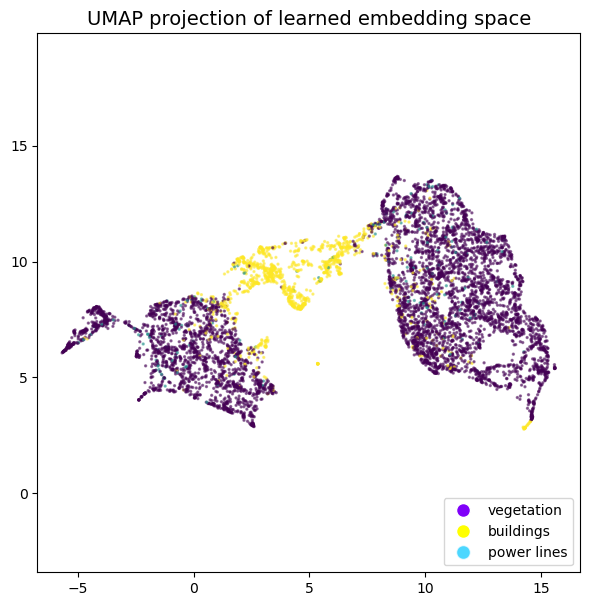

In [35]:
import matplotlib.pyplot as plt
path_plot='/home/m.caros/work/3DSemanticSegmentation/src/bt/figures'
name='UMAP_PN2_BT_3classes'
plt.rcParams["figure.figsize"] = (7,7)
from matplotlib.lines import Line2D

plt.scatter(
    embedding[:, 0],
    embedding[:, 1],
    alpha=0.5,
    c=embed_df['label'],
    s=2)
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of learned embedding space', fontsize=14)

# Legend
yellow = np.array([256 / 256, 256 / 256, 0 / 256, 1]) 
blue = np.array([0 / 256, 200 / 256, 1, 0.7])
purple = np.array([127 / 256, 0 / 256, 250 / 256, 1])
    
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='vegetation', markerfacecolor=purple, markersize=10),
    Line2D([0], [0], marker='o', color='w', label='buildings and infrastructures', markerfacecolor=yellow, markersize=10),
    Line2D([0], [0], marker='o', color='w', label='power lines', markerfacecolor=blue, markersize=10),
]

plt.legend(handles=legend_elements, loc='lower right')  # , bbox_to_anchor=(1.04, 0.5)
fig.tight_layout(pad=0.4)

plt.savefig(os.path.join(path_plot, name) + '.png', dpi=200)  # str(len(labels[labels==1])) +


In [21]:
embed_df['embed'].shape

(6710, 512)

In [22]:
from sklearn.decomposition import PCA
pca = PCA(n_components=3)
pca.fit(embed_df['embed'])
pca = pca.transform(embed_df['embed'])
pca.shape

(6710, 3)

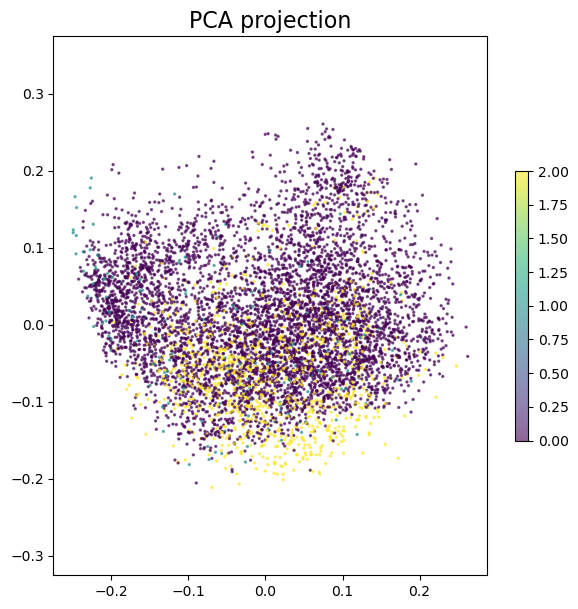

In [23]:
sc=plt.scatter(
    pca[:, 0],
    pca[:, 1],
    alpha=0.6,
    c=embed_df['label'],
    s=2)
plt.gca().set_aspect('equal', 'datalim')
plt.title('PCA projection', fontsize=16)
plt.colorbar(sc, shrink=0.5, pad=0.05)


IndexError: index 2 is out of bounds for axis 1 with size 2

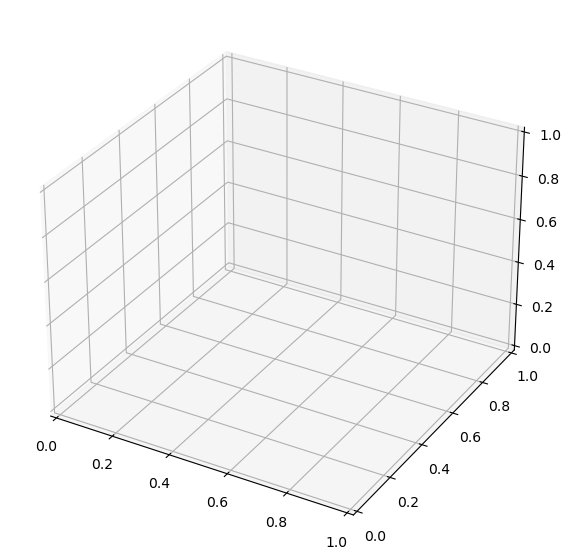

In [24]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')


ax.scatter(embedding[:, 0], embedding[:, 1], embedding[:, 2], c=embed_df['label'], marker='o')

### Init Simple classifier

In [ ]:
cls = Classifier(num_classes=2,
                 encoder=encoder,
                 num_training_samples=len(test_dataset),
                 batch_size=BATCH_SIZE,
                 max_epochs=None,
                 learning_rate=0.001, 
                 dropout=0.3).cuda()


## Test Classifier with Barlow Twins vector

In [ ]:
# ckpt_dict = torch.load('checkpoints_tower_cls/epoch=4-step=8220.ckpt')  
# cls.load_state_dict(ckpt_dict['state_dict'])


In [ ]:
model = cls.load_from_checkpoint(
    checkpoint_path='checkpoints_tower_cls/epoch=18-step=31236.ckpt',
    hparams_file="lightning_log/sversion_3/hparams.yaml",
    map_location='cuda',
    num_classes=2,
    encoder=encoder,
    num_training_samples=len(test_dataset),
    batch_size=BATCH_SIZE
)


In [ ]:
len(test_dataset)

In [ ]:
torch.set_float32_matmul_precision('medium')

In [ ]:
# BATCH SIZE = 1
trainer = Trainer(
    accelerator="auto",
    devices=1 if torch.cuda.is_available() else None)

# test (pass in the model)
trainer.test(model, dataloaders=test_loader)

In [ ]:
# batch=123
for i in range(10, 201):
    if len(test_dataset) % i == 0:
        print(i)